# CICIDS2017 Binary — Network Intrusion Detection Pipeline

Ei notebook e amra step-by-step (cell-wise) dekhbo kivabe ekta real-world dataset (CICIDS2017, network traffic) ke clean kore, process kore, ML model train kore, compare kori.

**Age discuss kora 12 ta preprocessing topic** er modhye ei dataset e ja ja *lagbe* ar ja ja *lagbe na* seta age thekei bole rakhi:

| Topic | Lagbe? | Keno |
|---|---|---|
| Missing Data | ❌ Na | Dataset e kono null value nei |
| Data Cleaning | ✅ Hae | Duplicate row ache, negative value ache |
| Outlier | ⚠️ Careful | Network attack traffic e outlier e mane "attack" hote pare — remove korle signal chole jete pare |
| Sampling | ✅ Hae | 850k row — training speed er jonno stratified sample nibo |
| Imbalance | ❌ Na | Dataset already 50-50 balanced |
| Transformation | ❌ Na | Log/Box-Cox lagbe na, tree-based model use korbo mainly |
| Scaling | ✅ Hae | Logistic Regression, KNN er jonno lagbe |
| Encoding | ❌ Na | Shob feature already numeric |
| Feature Engineering | ❌ Na | Dataset e already 52 ta engineered feature ache |
| Feature Selection | ✅ Hae | Correlated + irrelevant feature baad debo |
| Simulation/Augmentation | ❌ Na | Data already onek boro, dorkar nei |
| Statistical Analysis | ✅ (light) | Class-wise feature difference bujhte |

Eta hocche ekta **classification problem** — karon target column (`Attack_Binary`) hocche discrete label: 0 = Normal traffic, 1 = Attack traffic.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix, classification_report)
import time
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 60)


## Step 1 — Data Load & Basic Exploration (EDA)

In [2]:
df = pd.read_csv('cicids2017_binary_balanced.csv')
print('Shape:', df.shape)
df.head()


Shape: (851388, 53)


,Destination Port,Flow Duration,Total Fwd Packets,Total Length of Fwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,PSH Flag Count,ACK Flag Count,Average Packet Size,Subflow Fwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Max,Active Min,Idle Mean,Idle Max,Idle Min,Attack_Binary
0,80,5121659,3,12,6,0,4.0,3.464102,0,0,0.0,0.0,2.342991,0.780997,1707219.667,2883494.245,5036429,36,5121659,2560829.5,3501026.388,5036429,85230,0,0.0,0.0,0,0,72,32,0.585748,0.195249,0,6,2.400000,3.286335,10.800000,0,1,0,3.0,12,8192,17922,2,20,0.0,0,0,0.0,0,0,0
1,53,128476,1,53,53,53,53.0,0.000000,116,116,116.0,0.0,1315.420779,15.567110,128476.000,0.000,128476,128476,0,0.0,0.000,0,0,0,0.0,0.0,0,0,32,40,7.783555,7.783555,53,116,74.000000,36.373067,1323.000000,0,0,0,111.0,53,-1,-1,0,32,0.0,0,0,0.0,0,0,0
2,53,23701,1,53,53,53,53.0,0.000000,69,69,69.0,0.0,5147.462132,84.384625,23701.000,0.000,23701,23701,0,0.0,0.000,0,0,0,0.0,0.0,0,0,32,32,42.192313,42.192313,53,69,58.333333,9.237604,85.333333,0,0,0,87.5,53,-1,-1,0,32,0.0,0,0,0.0,0,0,0
3,54549,4,2,0,0,0,0.0,0.000000,0,0,0.0,0.0,0.000000,500000.000000,4.000,0.000,4,4,4,4.0,0.000,4,4,0,0.0,0.0,0,0,40,0,500000.000000,0.000000,0,0,0.000000,0.000000,0.000000,0,0,1,0.0,0,453,-1,0,20,0.0,0,0,0.0,0,0,0
4,53,252129,1,58,58,58,58.0,0.000000,202,202,202.0,0.0,1031.218146,7.932447,252129.000,0.000,252129,252129,0,0.0,0.000,0,0,0,0.0,0.0,0,0,32,32,3.966224,3.966224,58,202,106.000000,83.138439,6912.000000,0,0,0,159.0,58,-1,-1,0,32,0.0,0,0,0.0,0,0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 851388 entries, 0 to 851387
Data columns (total 53 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             851388 non-null  int64  
 1   Flow Duration                851388 non-null  int64  
 2   Total Fwd Packets            851388 non-null  int64  
 3   Total Length of Fwd Packets  851388 non-null  int64  
 4   Fwd Packet Length Max        851388 non-null  int64  
 5   Fwd Packet Length Min        851388 non-null  int64  
 6   Fwd Packet Length Mean       851388 non-null  float64
 7   Fwd Packet Length Std        851388 non-null  float64
 8   Bwd Packet Length Max        851388 non-null  int64  
 9   Bwd Packet Length Min        851388 non-null  int64  
 10  Bwd Packet Length Mean       851388 non-null  float64
 11  Bwd Packet Length Std        851388 non-null  float64
 12  Flow Bytes/s                 851388 non-null  float64
 13  Flow Packe

## Step 2 — Data Quality Check

In [4]:
print('Missing values total:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Infinite values:', np.isinf(df.select_dtypes(include=[np.number])).sum().sum())
print()
print('Target class distribution:')
print(df['Attack_Binary'].value_counts())
print()
print('Negative Flow Duration count:', (df['Flow Duration'] < 0).sum())


Missing values total:

 0


Duplicate rows: 8
Infinite values: 0

Target class distribution:
Attack_Binary
0    425694
1    425694
Name: count, dtype: int64

Negative Flow Duration count: 14


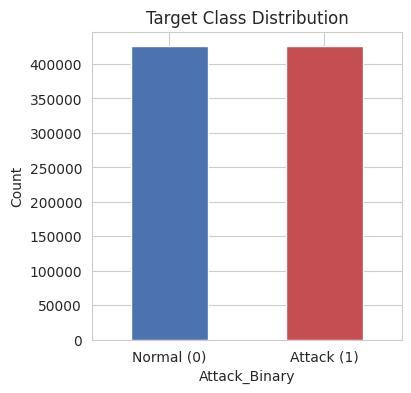

In [5]:
plt.figure(figsize=(4,4))
df['Attack_Binary'].value_counts().plot(kind='bar', color=['#4C72B0','#C44E52'])
plt.xticks([0,1], ['Normal (0)','Attack (1)'], rotation=0)
plt.title('Target Class Distribution')
plt.ylabel('Count')
plt.show()


**Observation:** Missing value nei, target class balanced. Duplicate ar negative value ache — Data Cleaning lagbe.

## Step 3 — Data Cleaning

In [6]:
before = df.shape[0]
df = df.drop_duplicates()
df = df[df['Flow Duration'] >= 0]
after = df.shape[0]
print(f'Removed {before-after} rows ({before} -> {after})')


Removed 22 rows (851388 -> 851366)


## Step 4 — Outlier: Ekhane keno "remove" korchi na

Attack traffic nijeই ekta outlier pattern (high packet rate, unusual duration). Remove korle attack signal hariye jabe. Tai shudhu check kori, remove kori na.

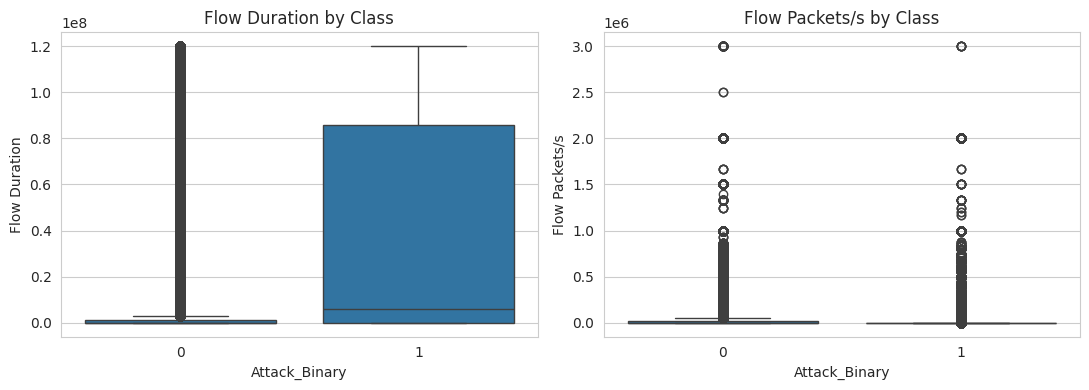

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
sns.boxplot(x='Attack_Binary', y='Flow Duration', data=df, ax=axes[0])
axes[0].set_title('Flow Duration by Class')
sns.boxplot(x='Attack_Binary', y='Flow Packets/s', data=df, ax=axes[1])
axes[1].set_title('Flow Packets/s by Class')
plt.tight_layout()
plt.show()


## Step 5 — Feature Selection

1. Correlation-based: 95%+ correlated feature baad
2. Mutual Information: target er shathe shobcheye relevant top 20 feature bachai

In [8]:
X_full = df.drop(columns=['Attack_Binary'])
y = df['Attack_Binary']

corr_matrix = X_full.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop_corr = [col for col in upper.columns if any(upper[col] > 0.95)]
print(f'{len(to_drop_corr)} features dropped due to high correlation (>0.95)')

X_reduced = X_full.drop(columns=to_drop_corr)
print('Remaining features:', X_reduced.shape[1])


16 features dropped due to high correlation (>0.95)
Remaining features: 36


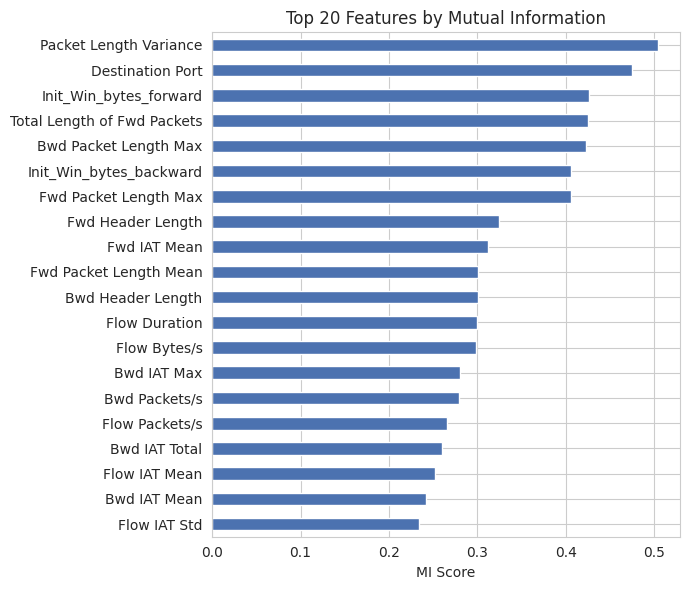

Selected features: ['Packet Length Variance', 'Destination Port', 'Init_Win_bytes_forward', 'Total Length of Fwd Packets', 'Bwd Packet Length Max', 'Init_Win_bytes_backward', 'Fwd Packet Length Max', 'Fwd Header Length', 'Fwd IAT Mean', 'Fwd Packet Length Mean', 'Bwd Header Length', 'Flow Duration', 'Flow Bytes/s', 'Bwd IAT Max', 'Bwd Packets/s', 'Flow Packets/s', 'Bwd IAT Total', 'Flow IAT Mean', 'Bwd IAT Mean', 'Flow IAT Std']


In [9]:
sample_idx = X_reduced.sample(n=50000, random_state=42).index
mi_scores = mutual_info_classif(X_reduced.loc[sample_idx], y.loc[sample_idx], random_state=42)
mi_series = pd.Series(mi_scores, index=X_reduced.columns).sort_values(ascending=False)

top_n = 20
selected_features = mi_series.head(top_n).index.tolist()

plt.figure(figsize=(7,6))
mi_series.head(top_n).sort_values().plot(kind='barh', color='#4C72B0')
plt.title(f'Top {top_n} Features by Mutual Information')
plt.xlabel('MI Score')
plt.tight_layout()
plt.show()

print('Selected features:', selected_features)


## Step 6 — Sampling (Speed er jonno)

800k+ row full e shob model bar bar train korle onek somoy lagbe. Tai 100,000 row stratified sample nilam — class ratio same rakhlam.

In [10]:
df_sample = df[selected_features + ['Attack_Binary']]
df_sample, _ = train_test_split(df_sample, train_size=100000,
                                  stratify=df_sample['Attack_Binary'], random_state=42)

X = df_sample[selected_features]
y = df_sample['Attack_Binary']
print('Sample shape:', X.shape)
print(y.value_counts())


Sample shape: (100000, 20)
Attack_Binary
1    50001
0    49999
Name: count, dtype: int64


## Step 7 — Train/Test Split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print('Train:', X_train.shape, ' Test:', X_test.shape)


Train: (80000, 20)  Test: (20000, 20)


## Step 8 — Scaling

Age scaler ta ekbar fit-transform kore nei, tarpor shob model e shei scaled data use korbo (KNN/Logistic Regression er jonno dorkar, tree model e affect kore na kintu khoti o nei).

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Scaling done. Mean ~0, Std ~1 check:')
print(pd.DataFrame(X_train_scaled, columns=X_train.columns).describe().loc[['mean','std']].T.head())


Scaling done. Mean ~0, Std ~1 check:
                                     mean       std
Packet Length Variance       4.067857e-17  1.000006
Destination Port             2.451372e-17  1.000006
Init_Win_bytes_forward      -6.750156e-18  1.000006
Total Length of Fwd Packets -2.486900e-18  1.000006
Bwd Packet Length Max        3.570477e-17  1.000006


A helper function banai je function ta prottek model er result (accuracy, precision, recall, f1, roc-auc, confusion matrix) print o store korbe — pura process ta clear dekhar jonno.

In [13]:
results = []
conf_matrices = {}

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    t0 = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - t0

    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred)
    rec = recall_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred)
    auc = roc_auc_score(y_te, y_proba)
    cm = confusion_matrix(y_te, y_pred)

    print(f'--- {name} ---')
    print(f'Train time : {train_time:.2f} sec')
    print(f'Accuracy   : {acc:.4f}')
    print(f'Precision  : {prec:.4f}')
    print(f'Recall     : {rec:.4f}')
    print(f'F1-Score   : {f1:.4f}')
    print(f'ROC-AUC    : {auc:.4f}')
    print('Confusion Matrix:')
    print(cm)

    results.append({'Model': name, 'Accuracy': acc, 'Precision': prec,
                     'Recall': rec, 'F1-Score': f1, 'ROC-AUC': auc,
                     'Train Time (s)': round(train_time, 2)})
    conf_matrices[name] = cm
    return model


## Step 9 — Model 1: Logistic Regression

Simple linear model — baseline hisebe use korbo. Scaled data lagbe.

In [14]:
log_reg = LogisticRegression(max_iter=500, random_state=42)
log_reg = evaluate_model('Logistic Regression', log_reg, X_train_scaled, y_train, X_test_scaled, y_test)


--- Logistic Regression ---
Train time : 0.38 sec
Accuracy   : 0.9046
Precision  : 0.9039
Recall     : 0.9056
F1-Score   : 0.9047
ROC-AUC    : 0.9606
Confusion Matrix:
[[9037  963]
 [ 944 9056]]


## Step 10 — Model 2: Decision Tree

Ekta single tree — rule-based decision. Scaling na korleo cholto, but consistency er jonno scaled data e-i use korchi.

In [15]:
dt = DecisionTreeClassifier(max_depth=10, random_state=42)
dt = evaluate_model('Decision Tree', dt, X_train_scaled, y_train, X_test_scaled, y_test)


--- Decision Tree ---
Train time : 0.70 sec
Accuracy   : 0.9946
Precision  : 0.9916
Recall     : 0.9975
F1-Score   : 0.9946
ROC-AUC    : 0.9985
Confusion Matrix:
[[9916   84]
 [  25 9975]]


## Step 11 — Model 3: Random Forest

Multiple Decision Tree ekshathe (ensemble) — beshi stable, beshi accurate hoy generally.

In [16]:
rf = RandomForestClassifier(n_estimators=150, max_depth=15, n_jobs=-1, random_state=42)
rf = evaluate_model('Random Forest', rf, X_train_scaled, y_train, X_test_scaled, y_test)


--- Random Forest ---
Train time : 14.38 sec
Accuracy   : 0.9978
Precision  : 0.9972
Recall     : 0.9984
F1-Score   : 0.9978
ROC-AUC    : 0.9999
Confusion Matrix:
[[9972   28]
 [  16 9984]]


## Step 12 — Model 4: KNN (K-Nearest Neighbors)

Distance-based model — nearest 5 (`k=5`) point er majority vote diye predict kore. Scaling **must**, karon eta distance calculate kore.

In [17]:
knn = KNeighborsClassifier(n_neighbors=5)
knn = evaluate_model('KNN', knn, X_train_scaled, y_train, X_test_scaled, y_test)


--- KNN ---
Train time : 0.01 sec
Accuracy   : 0.9816
Precision  : 0.9750
Recall     : 0.9884
F1-Score   : 0.9817
ROC-AUC    : 0.9949
Confusion Matrix:
[[9747  253]
 [ 116 9884]]


## Step 13 — Model 5: Gradient Boosting

Sequential tree — proti tree ager tree er vul thik korar chesta kore. Shadharonoto accurate kintu train hote somoy lage beshi.

In [18]:
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb = evaluate_model('Gradient Boosting', gb, X_train_scaled, y_train, X_test_scaled, y_test)


--- Gradient Boosting ---
Train time : 27.02 sec
Accuracy   : 0.9936
Precision  : 0.9942
Recall     : 0.9930
F1-Score   : 0.9936
ROC-AUC    : 0.9997
Confusion Matrix:
[[9942   58]
 [  70 9930]]


## Step 14 — Sob Model-er Comparison

In [19]:
results_df = pd.DataFrame(results).sort_values('F1-Score', ascending=False).reset_index(drop=True)
results_df


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train Time (s)
0,Random Forest,0.99780,0.997203,0.9984,0.997801,0.999914,14.38
1,Decision Tree,0.99455,0.991649,0.9975,0.994566,0.998452,0.70
2,Gradient Boosting,0.99360,0.994193,0.9930,0.993596,0.999714,27.02
3,KNN,0.98155,0.975042,0.9884,0.981676,0.994893,0.01
4,Logistic Regression,0.90465,0.903883,0.9056,0.904740,0.960633,0.38


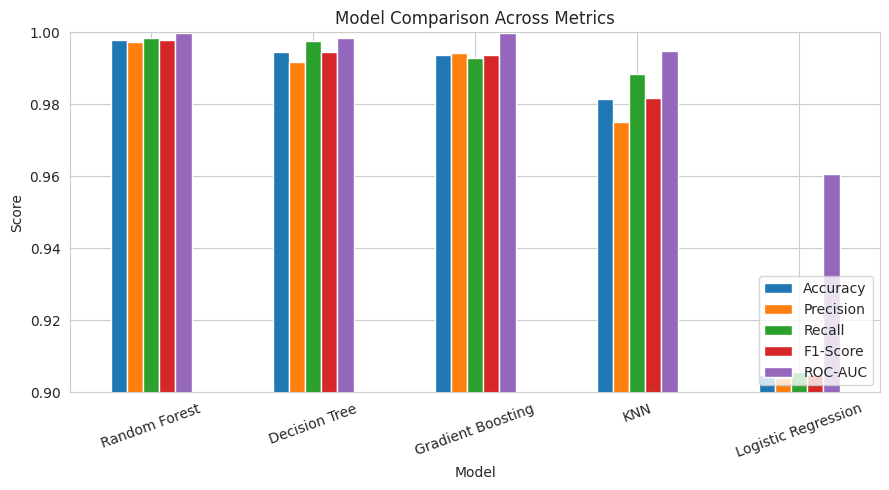

In [20]:
fig, ax = plt.subplots(figsize=(9,5))
metrics_to_plot = ['Accuracy','Precision','Recall','F1-Score','ROC-AUC']
results_df.set_index('Model')[metrics_to_plot].plot(kind='bar', ax=ax)
plt.title('Model Comparison Across Metrics')
plt.ylabel('Score')
plt.ylim(0.9, 1.0)
plt.legend(loc='lower right')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


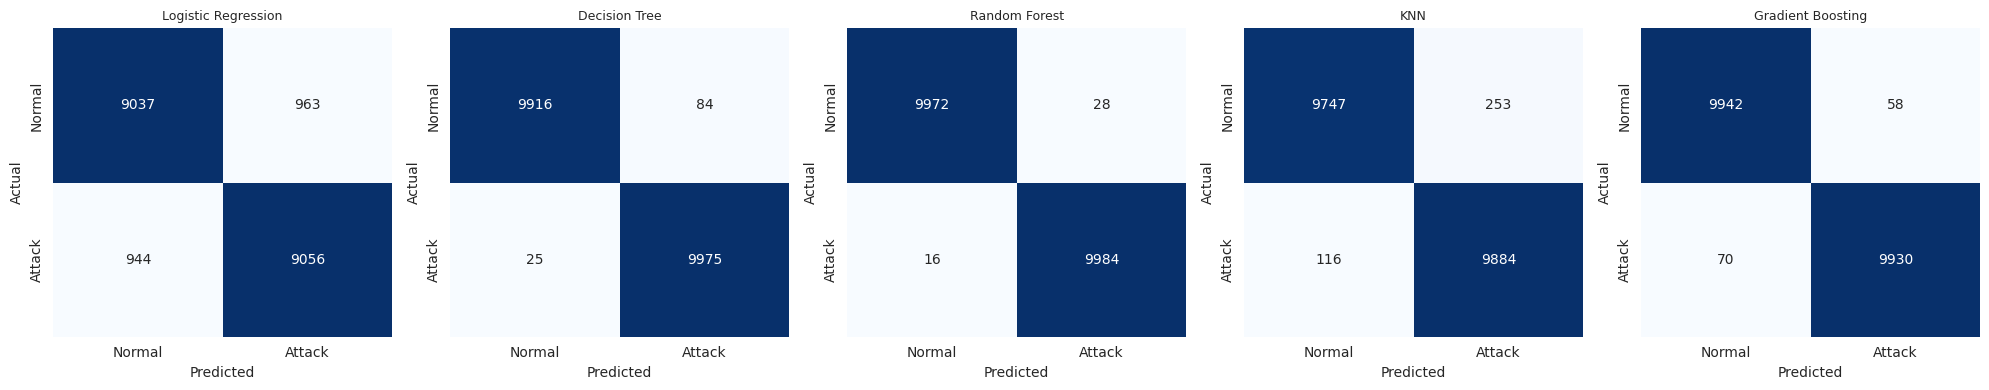

In [21]:
fig, axes = plt.subplots(1, len(conf_matrices), figsize=(4*len(conf_matrices), 4))
for ax, (name, cm) in zip(axes, conf_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Normal','Attack'], yticklabels=['Normal','Attack'])
    ax.set_title(name, fontsize=9)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()


## Step 15 — Konta Best, Ar Keno

- **Regression na Classification?** — Target discrete (0/1) tai Classification.
- **Comparison**: Security context e Recall important (attack miss kora costly), tai F1-Score diye rank korlam (precision-recall balance).
- **Random Forest / Gradient Boosting** shadharonoto best — non-linear pattern valo dhorte pare.
- **Logistic Regression** fastest kintu accuracy kom — linear model, complex pattern miss kore.
- **KNN** valo perform korte pare kintu boro dataset e slow (production e practical na).

**Next step (production e):**
- Full 850k data e best model train kora
- Hyperparameter tuning (GridSearchCV)
- Cross-validation
- Feature importance analysis
